# 01 · Exploratory Data Analysis — SPY Trading Signal Model

**Goal.** Understand the SPY daily data, the engineered features and the Buy / Hold / Sell target *before* any modelling.

**Information boundary.** Price-level descriptions use the whole 2005–2024 snapshot (a data audit). Anything that could steer modelling choices (feature distributions, correlations, target balance, threshold sensitivity) is computed on **Train (2010–2020)** and, where noted, **Validation (2021–2022)** only. **Test labels (2023–2024) are sealed** and never inspected here.

Run order: `01_eda` → `02_modeling` → `03_backtest`. All logic lives in `src/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data import load_snapshot, latest_snapshot_path, audit
from src.dataset import build_dataset
from src.features import FEATURE_COLS
from src.labels import to_class
from src.split import get_segments

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)
config.FIG_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(config.FIG_DIR / f"eda_{name}.png", dpi=120, bbox_inches="tight")

## 1. Data snapshot and audit

In [2]:
raw = load_snapshot()
print("Snapshot:", latest_snapshot_path().name)
display(raw.head(3)); display(raw.tail(3))
pd.Series(audit(raw), name="value").to_frame()

Snapshot: spy_20261010.csv


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,81.8216,81.9563,80.7043,80.9735,55748000
2005-01-04,81.0812,81.1351,79.7216,79.9841,69167600
2005-01-05,79.9235,80.2668,79.4254,79.4322,65667300


,Open,High,Low,Close,Volume
Date,,,,,
2024-12-27,586.0271,586.2625,579.3778,583.5459,64969300
2024-12-30,576.5632,580.3390,573.1502,576.8868,56578800
2024-12-31,578.5441,579.2601,573.1599,574.7880,57052700


,value
rows,5033
first_date,2005-01-03
last_date,2024-12-31
missing_values,0
duplicate_dates,0
unsorted_index,False
high_below_open_close,0
low_above_open_close,0
non_positive_volume,0
gaps_over_4_calendar_days,2


In [3]:
# Calendar gaps > 4 days and the largest daily moves (sanity check, not errors)
gaps = raw.index.to_series().diff().dt.days
print("Calendar gaps > 4 days:\n", gaps[gaps > 4])
ret = raw["Close"].pct_change()
print("\nLargest |daily return| days:\n", ret.abs().sort_values(ascending=False).head(8).round(4))

Calendar gaps > 4 days:
 Date
2007-01-03   5.0000
2012-10-31   5.0000
Name: Date, dtype: float64

Largest |daily return| days:
 Date
2008-10-13   0.1452
2008-10-28   0.1169
2020-03-16   0.1094
2008-10-15   0.0984
2020-03-12   0.0957
2020-03-24   0.0906
2008-12-01   0.0886
2020-03-13   0.0855
Name: Close, dtype: float64


*Audit notes.* No missing values, duplicates or OHLC inconsistencies. The two 5-day calendar gaps are genuine market closures (2 Jan 2007 national day of mourning; 29–30 Oct 2012 Hurricane Sandy), not missing data. Daily moves above 7% all fall in the 2008 crisis and March 2020 — real events, kept as is.

## 2. Price, returns and volatility

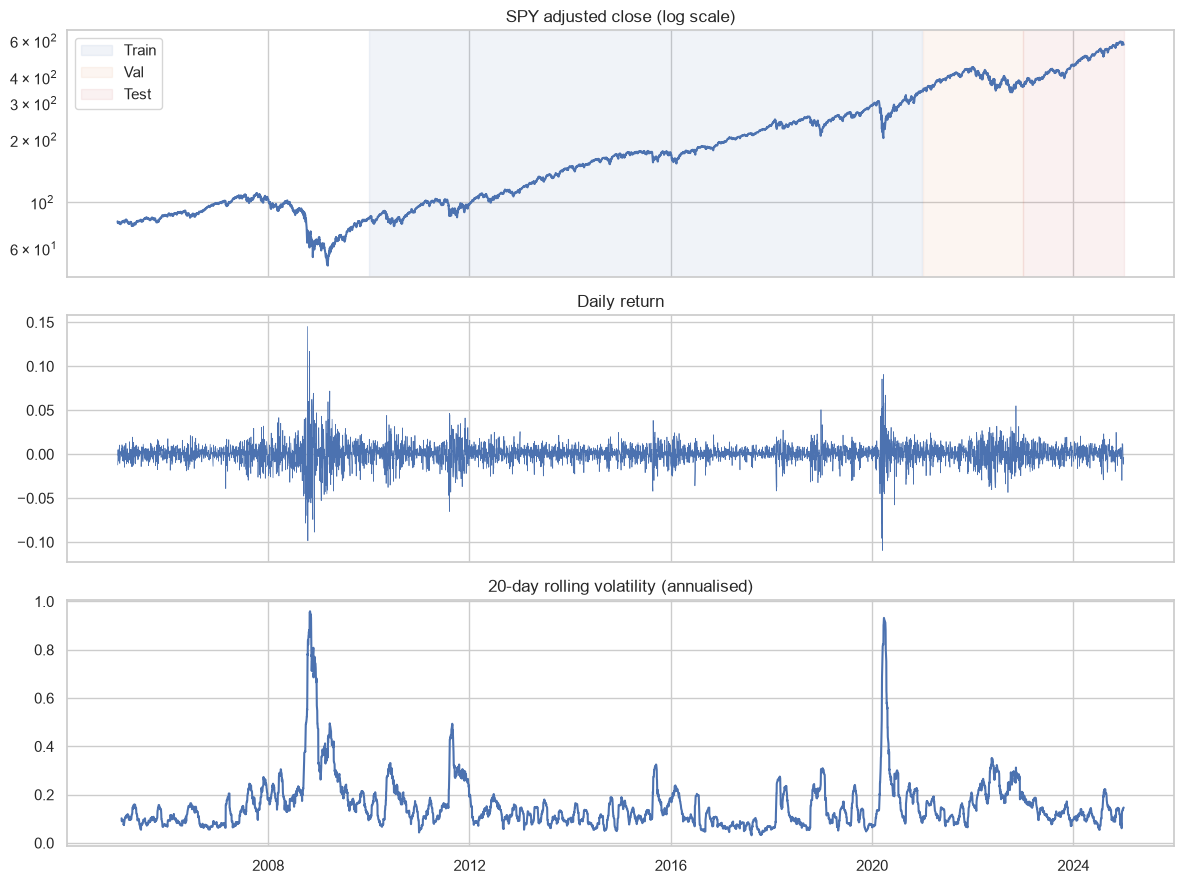

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(raw["Close"]); axes[0].set_yscale("log"); axes[0].set_title("SPY adjusted close (log scale)")
for name, (a, b) in {"Train": config.TRAIN, "Val": config.VAL, "Test": config.TEST}.items():
    axes[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), alpha=0.08, label=name, color={"Train":"C0","Val":"C1","Test":"C3"}[name])
axes[0].legend(loc="upper left")
axes[1].plot(ret, lw=0.5); axes[1].set_title("Daily return")
axes[2].plot(ret.rolling(20).std() * np.sqrt(252)); axes[2].set_title("20-day rolling volatility (annualised)")
plt.tight_layout(); savefig("price_returns_vol"); plt.show()

mean=0.00046  std=0.01199  skew=-0.08  excess kurtosis=14.93


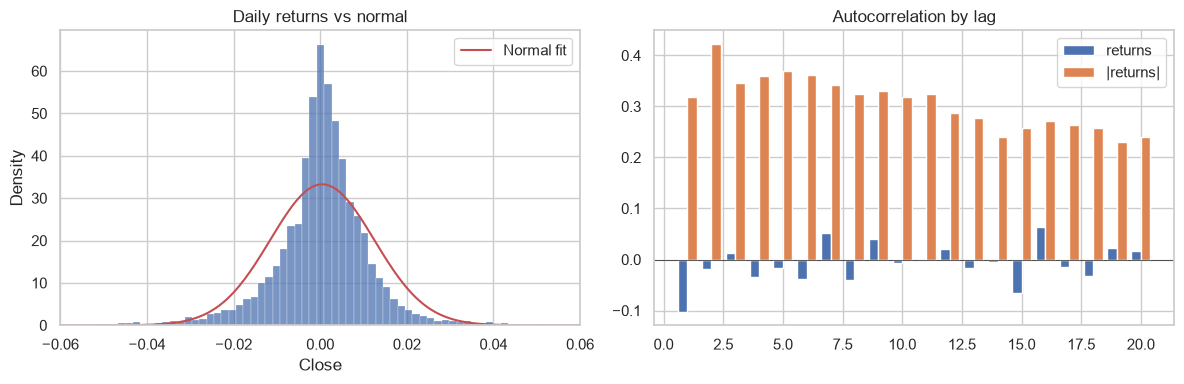

In [5]:
r = ret.dropna()
from scipy import stats
print(f"mean={r.mean():.5f}  std={r.std():.5f}  skew={stats.skew(r):.2f}  excess kurtosis={stats.kurtosis(r):.2f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(r, bins=150, stat="density", ax=ax[0]);
x = np.linspace(r.min(), r.max(), 400); ax[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r", label="Normal fit")
ax[0].set_xlim(-0.06, 0.06); ax[0].legend(); ax[0].set_title("Daily returns vs normal")
lags = range(1, 21)
ax[1].bar([l - 0.2 for l in lags], [r.autocorr(l) for l in lags], width=0.4, label="returns")
ax[1].bar([l + 0.2 for l in lags], [r.abs().autocorr(l) for l in lags], width=0.4, label="|returns|")
ax[1].axhline(0, color="k", lw=0.5); ax[1].legend(); ax[1].set_title("Autocorrelation by lag")
plt.tight_layout(); savefig("return_distribution_acf"); plt.show()

*Reading.* Daily returns are fat-tailed (large excess kurtosis) and close to uncorrelated with their own past, while **absolute** returns are strongly autocorrelated (volatility clustering). This is the core difficulty of the project: the *direction* of returns carries very little linear memory, volatility does.

## 3. Build features and labels; chronological segments

In [6]:
ds = build_dataset(raw)
segs = get_segments(ds)          # train / val only — test stays sealed
train, val = segs["train"], segs["val"]
print("Dataset rows (after warm-up):", len(ds), ds.index.min().date(), "→", ds.index.max().date())
for k, s in segs.items(): print(f"{k:5s}: {len(s):5d} rows  {s.index.min().date()} → {s.index.max().date()}")

Dataset rows (after warm-up): 4834 2005-10-17 → 2024-12-31
train:  2764 rows  2010-01-04 → 2020-12-23
val  :   498 rows  2021-01-04 → 2022-12-22


## 4. Feature distributions (training segment)

,mean,std,min,25%,50%,75%,max
ret_1,0.0006,0.0109,-0.1094,-0.0034,0.0007,0.0055,0.0906
ret_5,0.0028,0.0224,-0.1797,-0.0064,0.0046,0.0146,0.1736
ret_10,0.0056,0.0303,-0.2329,-0.0070,0.0082,0.0221,0.1880
ret_20,0.0112,0.0420,-0.3099,-0.0074,0.0163,0.0347,0.2307
close_sma20,0.0050,0.0239,-0.2008,-0.0047,0.0086,0.0188,0.1145
close_sma50,0.0128,0.0352,-0.2740,-0.0018,0.0186,0.0352,0.1325
close_sma200,0.0516,0.0525,-0.2568,0.0291,0.0608,0.0829,0.1785
sma20_sma50,0.0076,0.0216,-0.1422,-0.0018,0.0112,0.0208,0.0626
rsi_14,56.4644,11.3985,16.8027,48.6426,57.6635,64.9734,87.1922
macd_hist,-0.0000,0.0035,-0.0256,-0.0015,0.0001,0.0017,0.0214


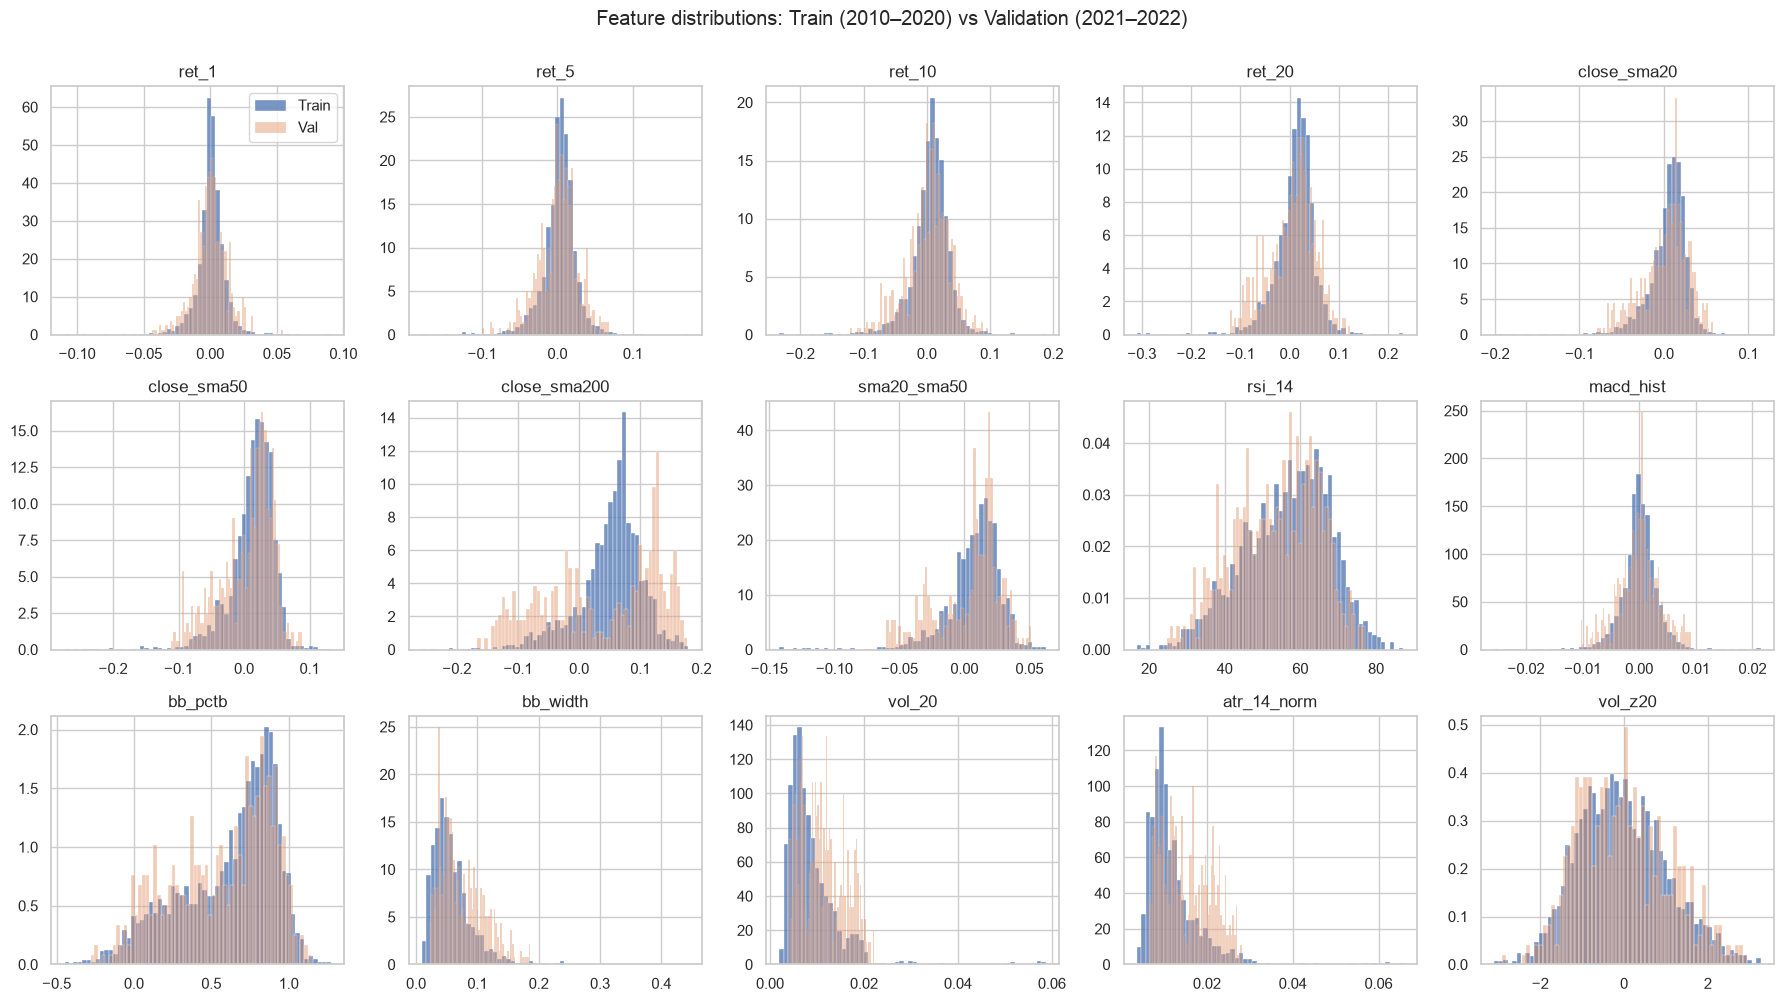

In [7]:
display(train[FEATURE_COLS].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]])
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, col in zip(axes.ravel(), FEATURE_COLS):
    sns.histplot(train[col], bins=60, ax=ax, stat="density", color="C0", label="Train")
    sns.histplot(val[col], bins=60, ax=ax, stat="density", color="C1", alpha=0.4, label="Val")
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
axes[0, 0].legend()
plt.suptitle("Feature distributions: Train (2010–2020) vs Validation (2021–2022)", y=1.0)
plt.tight_layout(); savefig("feature_distributions"); plt.show()

*Reading.* Return- and ratio-based features are roughly centred on zero (stationary by construction), while volatility features (`vol_20`, `atr_14_norm`, `bb_width`) are strongly right-skewed. Validation (2021–2022) shifts some distributions — e.g. `close_sma200` is lower because 2022 was a bear market — a reminder that the feature distribution is not stable over time.

## 5. Correlations between indicators (training segment)

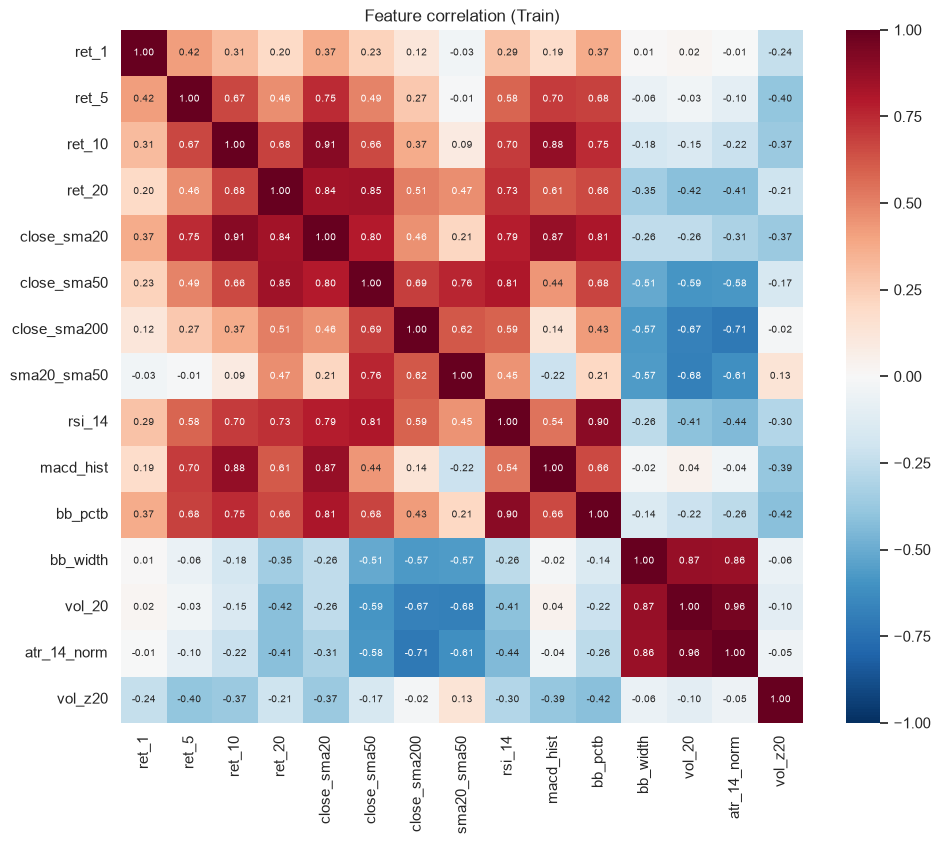

corr
vol_20      atr_14_norm 0.9603
ret_10      close_sma20 0.9086
rsi_14      bb_pctb     0.9034
ret_10      macd_hist   0.8772
bb_width    vol_20      0.8683
close_sma20 macd_hist   0.8683
bb_width    atr_14_norm 0.8625
ret_20      close_sma50 0.8463
            close_sma20 0.8404
close_sma20 bb_pctb     0.8127

In [8]:
corr = train[FEATURE_COLS].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Feature correlation (Train)"); savefig("feature_correlation"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
pairs.head(10).to_frame("corr")

*Reading.* Several indicators are near-duplicates (e.g. `bb_pctb` vs `rsi_14`, `vol_20` vs `atr_14_norm`, `ret_20` vs `close_sma20`). Many "different" technical indicators are re-expressions of the same recent-return information, so adding indicators adds less independent signal than it seems. This motivates the **compact feature-set ablation** in `02_modeling`.

## 6. Target: forward 5-day return and class balance

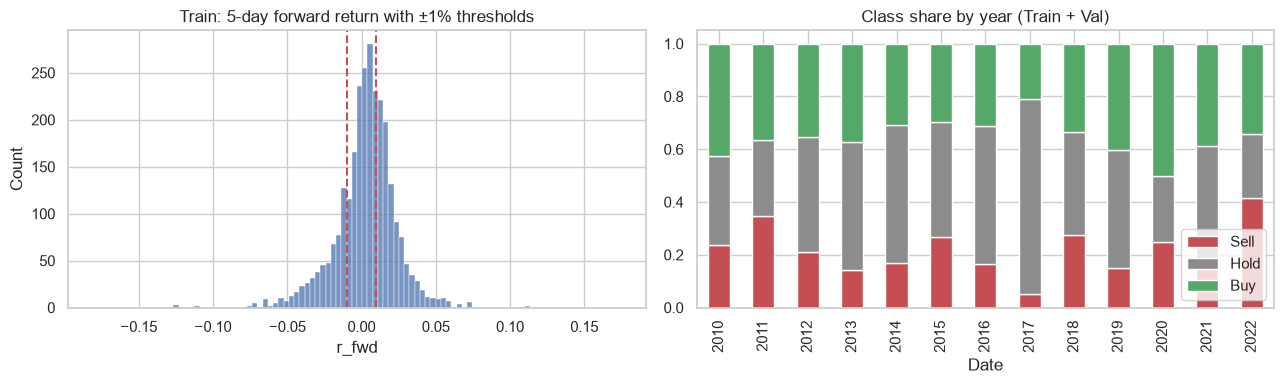

,train,val
label,,
Sell,0.2062,0.2912
Hold,0.4407,0.3434
Buy,0.3531,0.3655


In [9]:
tv = pd.concat([train, val])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["r_fwd"], bins=100, ax=ax[0])
for t in (config.BUY_THR, config.SELL_THR): ax[0].axvline(t, color="r", ls="--")
ax[0].set_title("Train: 5-day forward return with ±1% thresholds")
share = (tv.groupby(tv.index.year)["label"].value_counts(normalize=True).unstack()
           .rename(columns=config.CLASS_NAMES)[["Sell", "Hold", "Buy"]])
share.plot(kind="bar", stacked=True, ax=ax[1], color=["C3", "C7", "C2"])
ax[1].set_title("Class share by year (Train + Val)"); ax[1].legend(loc="lower right")
plt.tight_layout(); savefig("target_distribution"); plt.show()
bal = pd.DataFrame({k: s["label"].value_counts(normalize=True).rename(config.CLASS_NAMES) for k, s in segs.items()})
bal.loc[["Sell", "Hold", "Buy"]]

In [10]:
# Threshold sensitivity on TRAIN only: how class balance changes with the band width
rows = {}
for thr in [0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02]:
    rows[f"±{thr:.2%}"] = to_class(train["r_fwd"], thr, -thr).value_counts(normalize=True).rename(config.CLASS_NAMES)
pd.DataFrame(rows).T[["Sell", "Hold", "Buy"]]

,Sell,Hold,Buy
±0.50%,0.2710,0.2395,0.4895
±0.75%,0.2377,0.3484,0.4139
±1.00%,0.2062,0.4407,0.3531
±1.25%,0.1722,0.5308,0.2970
±1.50%,0.1454,0.6147,0.2399
±2.00%,0.1129,0.7344,0.1527


In [11]:
# Overlapping labels: neighbouring 5-day forward returns share 4 of 5 days
print("Autocorrelation of r_fwd (train) at lags 1..6:",
      [round(train["r_fwd"].autocorr(l), 3) for l in range(1, 7)])

Autocorrelation of r_fwd (train) at lags 1..6: [np.float64(0.768), np.float64(0.562), np.float64(0.335), np.float64(0.12), np.float64(-0.08), np.float64(-0.052)]


*Reading.*
- With ±1% thresholds the classes are **imbalanced**: in training Hold ≈ 44%, Buy ≈ 35%, Sell ≈ 21% (upward drift makes Sell the minority). The mix **shifts strongly by year** — calm 2017 is 74% Hold and only 5% Sell, while 2022 (validation) is 41% Sell. Validation therefore has a very different class balance from training (Sell 29% vs 21%). → class weighting is required, macro-F1 is the selection metric, and per-year evaluation is essential.
- A narrower band (±0.5%) shrinks Hold; a wider band (±2%) makes Hold dominant. The threshold choice largely *defines* the difficulty of the task.
- `r_fwd` is strongly autocorrelated for lags 1–4 purely because windows overlap → effective sample size is ~5× smaller than the row count, and CV folds need a gap.

## 7. Do features separate the classes? (training segment)

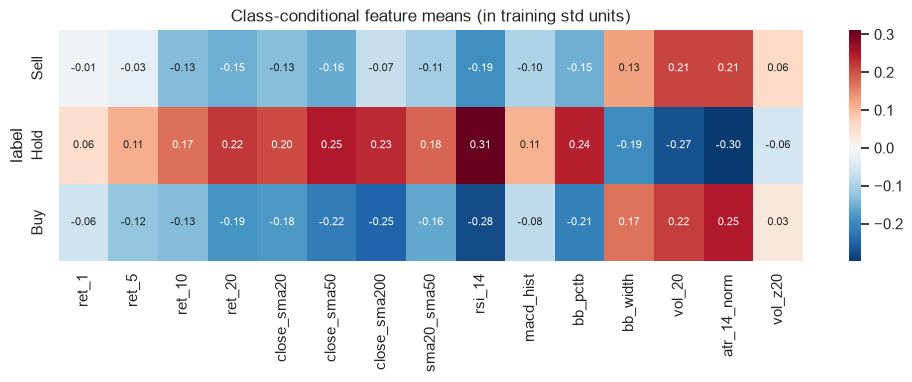

In [12]:
means = train.groupby("label")[FEATURE_COLS].mean().rename(index=config.CLASS_NAMES)
z = (means - train[FEATURE_COLS].mean()) / train[FEATURE_COLS].std()
plt.figure(figsize=(12, 3))
sns.heatmap(z.loc[["Sell", "Hold", "Buy"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 8})
plt.title("Class-conditional feature means (in training std units)"); savefig("class_conditional_means"); plt.show()

*Reading.* Class-conditional means differ by at most ~0.3 training standard deviations. The pattern is **Hold vs. "big move"**, not Buy vs. Sell:
- Hold days follow calm up-trends (higher RSI / momentum / `close_sma*`, lower volatility).
- Buy **and** Sell days both follow weaker momentum and higher volatility, with almost identical profiles (e.g. `vol_20` +0.21 vs +0.22, `rsi_14` −0.19 vs −0.28).

Volatility predicts *how big* the next 5-day move is, not *which direction*. Expect a modest signal that mainly separates Hold from the other two classes, and weak Buy-vs-Sell discrimination.

## 8. EDA conclusions → modelling decisions
1. Data is clean; snapshot is fixed for reproducibility.
2. Raw prices are non-stationary → only returns/ratios are used (done in `features.py`).
3. Strong redundancy among indicators → test a compact feature subset.
4. Imbalanced, time-varying classes → `class_weight="balanced"`, macro-F1, per-year evaluation.
5. Overlapping labels → `TimeSeriesSplit(gap=5)` and segment gaps (already enforced by tests).
6. Weak class separation, mainly Hold vs. not-Hold → expect macro-F1 only modestly above baselines, and many Buy↔Sell confusions.